(3000, 11)
Missing values: 0


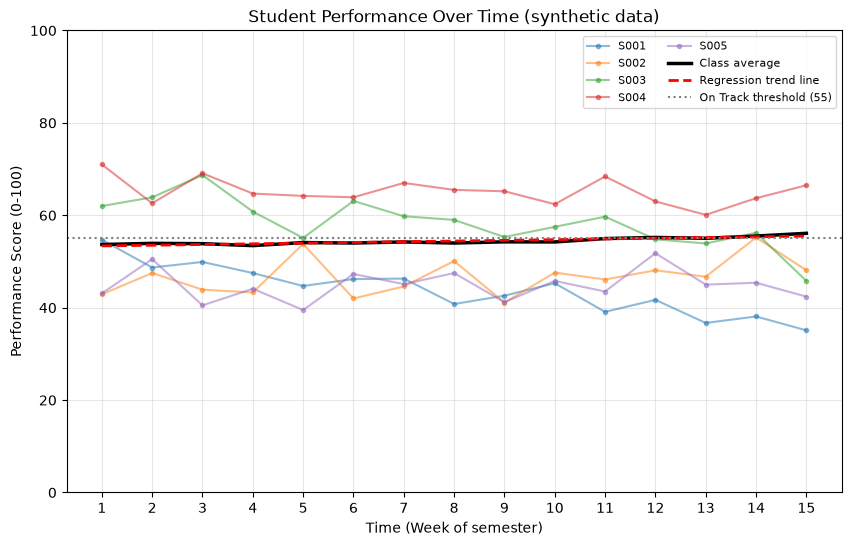

Trend: score changes by about 0.15 points per week on average


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("student_performance_timeseries.csv")
print(df.shape)
print("Missing values:", df.isnull().sum().sum())

avg = df.groupby("week")["performance_score"].mean()
slope, intercept = np.polyfit(df["week"], df["performance_score"], 1)

plt.figure(figsize=(10, 6))
for sid in ["S001", "S002", "S003", "S004", "S005"]:
    d = df[df["student_id"] == sid]
    plt.plot(d["week"], d["performance_score"], marker="o", markersize=3, alpha=0.5, label=sid)
plt.plot(avg.index, avg.values, color="black", linewidth=2.5, label="Class average")
plt.plot(avg.index, slope * avg.index + intercept, "r--", linewidth=2, label="Regression trend line")
plt.axhline(55, color="gray", linestyle=":", label="On Track threshold (55)")
plt.xlabel("Time (Week of semester)")
plt.ylabel("Performance Score (0-100)")
plt.title("Student Performance Over Time (synthetic data)")
plt.xticks(range(1, 16))
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.legend(ncol=2, fontsize=8)
plt.show()

print(f"Trend: score changes by about {slope:.2f} points per week on average")

Linear Regression: R2 = 0.947 | MAE = 2.12 | RMSE = 2.69
Random Forest Regressor: R2 = 0.933 | MAE = 2.38 | RMSE = 3.03


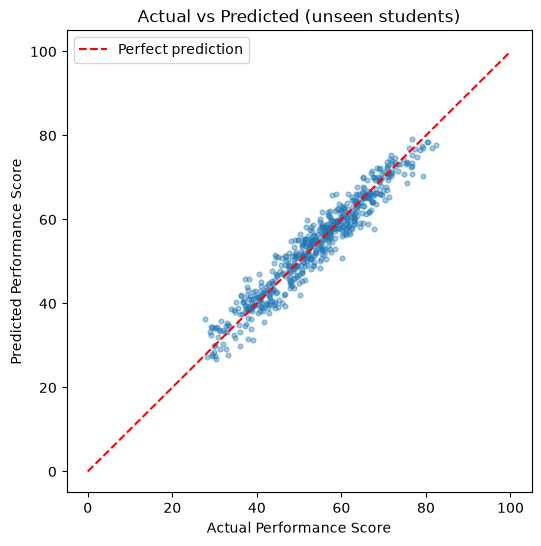

Saved model/student_regressor.joblib and model/regression_metrics.json


In [4]:
import json, joblib
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

FEATURES = ["week", "attendance", "study_hours", "previous_marks",
            "assignment_completion", "internal_marks", "failed_subjects", "sleep_hours"]
X, y = df[FEATURES], df["performance_score"]

# 80:20 split, keeping each student entirely in train or entirely in test
train_idx, test_idx = next(GroupShuffleSplit(test_size=0.2, random_state=42)
                           .split(X, y, groups=df["student_id"]))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=42),
}

results = {}
for name, m in models.items():
    m.fit(X_train, y_train)
    p = m.predict(X_test)
    results[name] = {"R2": r2_score(y_test, p),
                     "MAE": mean_absolute_error(y_test, p),
                     "RMSE": mean_squared_error(y_test, p) ** 0.5}
    print(f"{name}: R2 = {results[name]['R2']:.3f} | MAE = {results[name]['MAE']:.2f} | RMSE = {results[name]['RMSE']:.2f}")

# Graph: actual vs predicted on unseen students (Random Forest)
rf = models["Random Forest Regressor"]
pred = rf.predict(X_test)
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred, alpha=0.4, s=12)
plt.plot([0, 100], [0, 100], "r--", label="Perfect prediction")
plt.xlabel("Actual Performance Score")
plt.ylabel("Predicted Performance Score")
plt.title("Actual vs Predicted (unseen students)")
plt.legend()
plt.show()

joblib.dump(rf, "student_regressor.joblib")
with open("regression_metrics.json", "w") as f:
    json.dump(results, f, indent=2)
print("Saved model/student_regressor.joblib and model/regression_metrics.json")

In [6]:
%%writefile app.py
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import streamlit as st

BASE = Path(__file__).parent
MODEL_PATH = BASE / "student_regressor.joblib"
METRICS_PATH = BASE / "regression_metrics.json"
DATA_PATH = BASE / "student_performance_timeseries.csv"

THRESHOLD = 55          # score at or above this = On Track
MODEL_NAME = "Random Forest Regressor"

st.set_page_config(page_title="Student Performance Predictor", page_icon="🎓", layout="centered")

INPUT_KEYS = ["week", "attendance", "study_hours", "previous_marks",
              "assignment_completion", "internal_marks", "failed_subjects", "sleep_hours"]

LIMITS = {
    "week": ("Week of Semester", 1, 15),
    "attendance": ("Attendance Percentage", 0, 100),
    "study_hours": ("Average Study Hours Per Day", 0, 12),
    "previous_marks": ("Previous Examination Marks", 0, 100),
    "assignment_completion": ("Assignment Completion Percentage", 0, 100),
    "internal_marks": ("Internal Assessment Marks", 0, 100),
    "failed_subjects": ("Number of Previous Failed Subjects", 0, 10),
    "sleep_hours": ("Average Daily Sleep Hours", 0, 12),
}


@st.cache_resource
def load_model():
    return joblib.load(MODEL_PATH)


@st.cache_data
def load_metrics():
    with open(METRICS_PATH) as f:
        return json.load(f)


@st.cache_data
def load_data():
    return pd.read_csv(DATA_PATH)


def clear_inputs():
    for key in INPUT_KEYS:
        st.session_state[key] = None
    st.session_state["student_name"] = ""


def validate(name, values):
    """Return a list of error messages (empty list means all good)."""
    errors = []
    if not name.strip():
        errors.append("Please enter the Student ID or Name.")
    for key, (label, low, high) in LIMITS.items():
        value = values[key]
        if value is None:
            if key != "sleep_hours":          # sleep is optional
                errors.append(f"{label} is required.")
        elif value < low or value > high:
            errors.append(f"{label} must be between {low} and {high}.")
    return errors


def recommendations(v, needs_support):
    """Pick three supportive suggestions based on the entered values."""
    recs = []
    if v["attendance"] < 75:
        recs.append("Try to attend classes more regularly. Aim for at least 75% attendance, since class discussions make revision easier.")
    if v["study_hours"] < 2:
        recs.append("Create a simple daily timetable with 2 to 3 focused study hours, split into short sessions with breaks.")
    if v["assignment_completion"] < 70:
        recs.append("Complete and submit assignments on time. Breaking each one into small daily tasks can make this manageable.")
    if v["previous_marks"] < 50 or v["internal_marks"] < 50:
        recs.append("Identify the topics that were hardest in previous tests and ask your teacher for help with those first.")
    if v["failed_subjects"] >= 1:
        recs.append("Speak with your academic advisor about a plan to clear earlier backlogs step by step.")
    if v["sleep_hours"] is not None and v["sleep_hours"] < 6:
        recs.append("Aim for 7 to 8 hours of sleep. Good rest improves concentration and memory.")
    if needs_support:
        recs.append("Consider meeting a mentor or academic counsellor. Asking for guidance early is a strong and sensible step.")
    general = [
        "Keep up your current habits and review your progress every week.",
        "Form a small study group so you can explain topics to each other.",
        "Practise with past question papers to build confidence for exams.",
    ]
    return (recs + general)[:3]


def predict_score(model, values):
    row = pd.DataFrame([values])[list(model.feature_names_in_)]
    return float(np.clip(model.predict(row)[0], 0, 100))


# ------------------------------------------------------------------ PAGE
st.title("🎓 AI-Based Student Performance Predictor")
st.write("Enter a student's details to get an **estimated performance score (0-100)** from a "
         "Random Forest regression model, and see how the estimate looks over the semester.")

if not MODEL_PATH.exists():
    st.error("Model file 'model/student_regressor.joblib' was not found. Please run Cell B in the "
             "Jupyter Notebook first, and make sure app.py is in the same folder as the 'model' folder.")
    st.stop()

model = load_model()
tab_predict, tab_time, tab_info = st.tabs(["📝 Predict", "📈 Performance Over Time", "📊 Model Information"])

# ------------------------------------------------------------------ PREDICT
with tab_predict:
    with st.form("student_form"):
        name = st.text_input("Student ID or Name", key="student_name",
                             help="Used only to label this result. It is not used by the model.")
        c1, c2 = st.columns(2)
        with c1:
            week = st.number_input("Week of Semester (1-15)", 1, 15, value=None, step=1,
                                   key="week", placeholder="e.g. 8")
            attendance = st.number_input("Attendance Percentage (0-100)", 0.0, 100.0,
                                         value=None, step=1.0, key="attendance", placeholder="e.g. 82")
            previous_marks = st.number_input("Previous Examination Marks % (0-100)", 0.0, 100.0,
                                             value=None, step=1.0, key="previous_marks", placeholder="e.g. 68")
            internal_marks = st.number_input("Internal Assessment Marks % (0-100)", 0.0, 100.0,
                                             value=None, step=1.0, key="internal_marks", placeholder="e.g. 70")
        with c2:
            study_hours = st.number_input("Average Study Hours Per Day (0-12)", 0.0, 12.0,
                                          value=None, step=0.5, key="study_hours", placeholder="e.g. 3.5")
            assignment_completion = st.number_input("Assignment Completion % (0-100)", 0.0, 100.0,
                                                    value=None, step=1.0, key="assignment_completion", placeholder="e.g. 90")
            failed_subjects = st.number_input("Previous Failed Subjects (0-10)", 0, 10,
                                              value=None, step=1, key="failed_subjects", placeholder="e.g. 0")
            sleep_hours = st.number_input("Average Daily Sleep Hours (0-12, optional)", 0.0, 12.0,
                                          value=None, step=0.5, key="sleep_hours", placeholder="optional, default 7")

        b1, b2 = st.columns(2)
        predict_clicked = b1.form_submit_button("Predict Performance", type="primary", use_container_width=True)
        b2.form_submit_button("Clear Inputs", on_click=clear_inputs, use_container_width=True)

    if predict_clicked:
        values = {
            "week": week, "attendance": attendance, "study_hours": study_hours,
            "previous_marks": previous_marks, "assignment_completion": assignment_completion,
            "internal_marks": internal_marks, "failed_subjects": failed_subjects,
            "sleep_hours": sleep_hours,
        }
        errors = validate(name, values)
        if errors:
            for e in errors:
                st.error(e)
        else:
            try:
                note = None
                if values["sleep_hours"] is None:
                    values["sleep_hours"] = 7.0
                    note = "Sleep hours were not entered, so 7.0 hours was assumed."

                score = predict_score(model, values)
                needs_support = score < THRESHOLD
                label = "Needs Support" if needs_support else "On Track"

                # typical error from the saved evaluation (if available)
                mae = None
                if METRICS_PATH.exists():
                    mae = load_metrics().get(MODEL_NAME, {}).get("MAE")

                st.divider()
                st.subheader("Prediction Result")
                st.write(f"**Student:** {name.strip()}  |  **Week:** {int(values['week'])}")
                st.metric("Predicted Performance Score", f"{score:.1f} / 100")
                if needs_support:
                    st.warning(f"Category: **{label}** (score below {THRESHOLD})")
                else:
                    st.success(f"Category: **{label}** (score {THRESHOLD} or above)")
                st.progress(min(max(score / 100, 0.0), 1.0))
                if mae is not None:
                    st.caption(f"On unseen test students, this model's typical error was about "
                               f"±{mae:.1f} points, so treat the score as an estimate, not a guarantee.")
                else:
                    st.caption("This score is an estimate, not a guarantee of any academic outcome.")
                if note:
                    st.info(note)

                # ---- graph: X = week, Y = predicted score
                weeks = list(range(1, 16))
                proj = [predict_score(model, {**values, "week": w}) for w in weeks]
                fig, ax = plt.subplots(figsize=(8, 4.5))
                ax.plot(weeks, proj, marker="o", color="#1f77b4",
                        label="Predicted score (entered values kept constant)")
                ax.scatter([values["week"]], [score], color="red", s=90, zorder=5,
                           label=f"Selected week ({int(values['week'])})")
                if DATA_PATH.exists():
                    avg = load_data().groupby("week")["performance_score"].mean()
                    ax.plot(avg.index, avg.values, color="black", linestyle="--", label="Class average (dataset)")
                ax.axhline(THRESHOLD, color="gray", linestyle=":", label=f"On Track threshold ({THRESHOLD})")
                ax.set_xlabel("Time (Week of semester)")
                ax.set_ylabel("Performance Score (0-100)")
                ax.set_title("Predicted Performance Over Time")
                ax.set_xticks(weeks)
                ax.set_ylim(0, 100)
                ax.grid(alpha=0.3)
                ax.legend(fontsize=8)
                st.pyplot(fig)
                plt.close(fig)
                st.caption("The line shows what the model predicts if these same habits continued every week. "
                           "It is a what-if view, not a forecast of real events.")

                st.markdown("**Summary of entered information**")
                summary = pd.DataFrame({
                    "Item": [LIMITS[k][0] for k in INPUT_KEYS],
                    "Value": [str(values[k]) for k in INPUT_KEYS],
                })
                st.table(summary)

                st.markdown("**Three supportive suggestions**")
                for i, r in enumerate(recommendations(values, needs_support), start=1):
                    st.write(f"{i}. {r}")

                st.info("⚠️ Disclaimer: This is an estimate made by a Machine Learning model trained on "
                        "synthetic (artificial) data. It is not a permanent label and should not be used "
                        "for real academic decisions.")
            except Exception as err:
                st.error(f"Something went wrong while predicting: {err}")

# ------------------------------------------------------- PERFORMANCE OVER TIME
with tab_time:
    st.subheader("Performance Over Time (training dataset)")
    if DATA_PATH.exists():
        data = load_data()
        avg = data.groupby("week")["performance_score"].mean()
        slope, intercept = np.polyfit(data["week"], data["performance_score"], 1)

        fig, ax = plt.subplots(figsize=(8, 4.5))
        for sid in data["student_id"].unique()[:5]:
            d = data[data["student_id"] == sid]
            ax.plot(d["week"], d["performance_score"], marker="o", markersize=3, alpha=0.5, label=sid)
        ax.plot(avg.index, avg.values, color="black", linewidth=2.5, label="Class average")
        ax.plot(avg.index, slope * avg.index + intercept, "r--", linewidth=2, label="Regression trend line")
        ax.axhline(THRESHOLD, color="gray", linestyle=":", label=f"On Track threshold ({THRESHOLD})")
        ax.set_xlabel("Time (Week of semester)")
        ax.set_ylabel("Performance Score (0-100)")
        ax.set_xticks(range(1, 16))
        ax.set_ylim(0, 100)
        ax.grid(alpha=0.3)
        ax.legend(ncol=2, fontsize=8)
        st.pyplot(fig)
        plt.close(fig)
        st.write(f"Trend line: the average score changes by about **{slope:.2f} points per week**.")
        st.caption("This dataset is synthetic (artificially generated), so this graph shows the demo data, not real students.")
    else:
        st.warning("Dataset file 'data/student_performance_timeseries.csv' was not found.")

# --------------------------------------------------------------- MODEL INFO
with tab_info:
    st.subheader("About the Model")
    st.write("**Task:** Regression (predicts a number from 0 to 100).")
    st.write(f"**Algorithm used by this website:** {MODEL_NAME} (Scikit-learn), a group of decision trees whose predictions are averaged.")
    st.write("**Input features:** " + ", ".join(model.feature_names_in_))
    st.write("**Not used as a feature:** student name or ID.")
    st.write(f"**Category rule:** score of {THRESHOLD} or above = On Track, otherwise Needs Support.")
    st.write("**Training process:** the data was split 80% for training and 20% for testing. "
             "The split was done by student, so test students were never seen during training.")

    if METRICS_PATH.exists():
        m = load_metrics()
        st.markdown("**Evaluation on unseen test students**")
        rows = []
        for model_label, res in m.items():
            rows.append({"Model": model_label,
                         "R2": round(res["R2"], 3),
                         "MAE": round(res["MAE"], 2),
                         "RMSE": round(res["RMSE"], 2)})
        st.table(pd.DataFrame(rows))
        st.caption("R2: closer to 1 is better. MAE and RMSE: average error in score points, lower is better.")
    else:
        st.warning("regression_metrics.json not found. Run Cell B in the notebook to create it.")

    if hasattr(model, "feature_importances_"):
        st.markdown("**Feature importance**")
        imp = pd.Series(model.feature_importances_, index=model.feature_names_in_).sort_values()
        st.bar_chart(imp)

    st.markdown("**Important limitations**")
    st.write("- The data is **synthetic**. Scores came from an assumed formula plus random noise, not real student results.")
    st.write("- Good metrics here only show the model learned that formula. They do **not** prove real-world accuracy.")
    st.write("- Only a few factors are used. Many real influences (health, family situation, teaching quality) are missing.")
    st.write("- Predictions are estimates and should never be treated as guaranteed outcomes.")

Overwriting app.py
